# 1. Набор данных

CSV-файл с часовым разрешением (каждая строка — один час), период с 01.01.2024 по 31.12.2025 по времени Будапешта. В столбце timestamp время указано в UTC, поэтому первая строка — 2023-12-31 23:00 UTC.


**Задача: прогнозирование цены на wholesale рынке электроэнергии Венгрии (Day-Ahead)**

**Целевая переменная:
price_eur_mwh** — цена электроэнергии на рынке на сутки вперёд (Day-Ahead), €/МВт·ч.
Цена может быть очень низкой и даже отрицательной, особенно в солнечные часы.

**Признаки** (все это прогнозы на сутки вперёд, известные заранее):

*demand_forecast_mwh* — потребление электроэнергии, МВт·ч

*solar_forecast_mwh* — выработка солнечных станций, МВт·ч

*wind_forecast_mwh* — выработка ветровых станций, МВт·ч

*nuclear_forecast_mwh* — выработка АЭС, МВт·ч

*temperature_forecast_c* — температура, °C

*net_exchange_forecast_mwh* — чистый экспорт (перетоки с соседними странами), МВт·ч.

# 2. Import библиотек

In [36]:
import pandas as pd
import numpy as np
import seaborn as sns; sns.set()

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import holidays

import os
import sklearn
import statsmodels
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from google.colab import files
from plotly.subplots import make_subplots
from pathlib import Path

sns.set_style('white')
sns.set(rc={'figure.figsize':(11, 4)})

warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 3. Загрузка данных и анализ данныx

Цель разведывательного анализа данных - попытка предварительного понимания того, с чем вы имеете дело. Например, результатами анализа могут быть удаление аномалий, заполнение (удаление) пропусков, визуализация данных, выделение признаков или получение (или преобразование) новых признаков, удаление некоторых шумов, помех или других нерегулярных значений.

In [38]:
df = pd.read_csv('/content/drive/MyDrive/year_project/data_with_features.csv', delimiter = ',')

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   timestamp                  17544 non-null  object 
 1   price_eur_mwh              17544 non-null  float64
 2   demand_forecast_mwh        17544 non-null  float64
 3   solar_forecast_mwh         17544 non-null  float64
 4   net_exchange_forecast_mwh  17544 non-null  float64
 5   wind_forecast_mwh          17544 non-null  float64
 6   nuclear_forecast_mwh       17544 non-null  float64
 7   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.1+ MB


 В данных нет пропусков, все признаки кроме timestamp представляют собой числовые признаки. Целевая переменная также является числовой величиной

In [40]:
# Для удобства работы с числовыми признаками
time_columns = []
num_columns = []

for column_name in df.columns:
    if (df[column_name].dtypes == object):
        time_columns +=[column_name]
    else:
        num_columns +=[column_name]

print(' Время данные:\t ',time_columns, '\n Число столблцов = ',len(time_columns))

print('Числовые данные:\t ',  num_columns, '\n Число столблцов = ',len(num_columns))


 Время данные:	  ['timestamp'] 
 Число столблцов =  1
Числовые данные:	  ['price_eur_mwh', 'demand_forecast_mwh', 'solar_forecast_mwh', 'net_exchange_forecast_mwh', 'wind_forecast_mwh', 'nuclear_forecast_mwh', 'temperature_forecast_c'] 
 Число столблцов =  7


### 3.1 Анализ числовых признаков

Статистика по числовым данным

In [41]:
df.describe()

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,104.658552,4932.654702,709.517923,-1096.129697,66.320306,1740.107361,12.610484
std,73.143194,849.932015,1021.831947,1332.193201,61.657125,222.590801,9.351000
min,-210.050000,2303.430000,0.000000,-5365.300000,0.550000,1372.250000,-7.030000
25%,72.830000,4290.282500,0.000000,-2064.225000,16.522500,1440.000000,4.880000
50%,97.675000,4860.755000,34.925000,-1299.750000,47.130000,1900.000000,12.050000
75%,126.352500,5504.685000,1266.182500,-219.200000,97.457500,1900.000000,19.990000
max,999.010000,7442.800000,4329.080000,3819.900000,291.830000,1949.500000,35.910000


**Выводы по статистике числовых признаков**

Необходимо сравнивать среднее с медианой и смотреть на отношения между столбцами

**1 price_eur_mwh** Распределение скошено вправо, тяжёлые хвосты с обеих сторон: отрицательные цены и пики до 999. Хвосты — не мусор, их нужно предсказывать; логарифм неприменим, симметризация через arcsinh

**2 demand_forecast_mwh** Почти симметрично, но размах большой: ночной минимум втрое меньше пикового спроса. Час спроса — главный драйвер цены, разброс сам по себе информативен

**3 solar_forecast_mwh** Классический признак «ночь/день»: не менее половины часов — нулевая генерация. Среднее здесь бессмысленно как «типичное значение». Признак по природе бимодальный — линейные агрегаты его плохо описывают, а максимум 4329 покрывает до ~58% пикового спроса, что объясняет отрицательные цены в полдень

**4 net_exchange_forecast_mwh** Венгрия в среднем нетто-импортёр, но диапазон двусторонний: бывают часы сильного экспорта (+3800).

**5 wind_forecast_mwh** Ветер мал по величине и скошен: почти весь — в нижних значениях. На цену в Венгрии он влияет слабо; признак скорее «гигиенический», чем сильный

**6 nuclear_forecast_mwh** Квартили совпадают с медианой — признак дискретный: несколько рабочих уровней (полная мощность ~1900–1950 и пониженные режимы ~1370–1440). Атом надо кодировать категориально/порогами, а не как непрерывную величину

**7 temperature_forecast_c** Полный климатический диапазон: есть и отопительный сезон, и жара. Эффект температуры на спрос U-образный (холод и жара повышают спрос) — линейная подача в модель неверна

**Сравнение масштабов показывает, что главный структурный признак — остаточная нагрузка**. Средний спрос ~4933 MWh покрывается атомом (1740) в среднем лишь на треть, солнцем на ~14%, ветром на ~1%, остальное — импорт (в среднем −1096) и другие источники, которых нет в данных. Значит модель, не имеющая явно агрегата «спрос минус солнце минус ветер минус атом», будет собирать эту комбинацию косвенно — лучше посчитать её самому.

Таблица уже подсказывает про выбросы, не открывая график: у цены расстояние от IQR до min (−210 против 72,8) и до max (999 против 126,4) — в разы больше, чем сам IQR. Это ожидаемые рыночные события, а не ошибки измерения: стоит проверить, в какие часы они приходятся (ночные полдни выходных — вниз, зимние/летние вечера — вверх), прежде чем что-то «чистить».

### Распределение значений по каждому числовому признаку


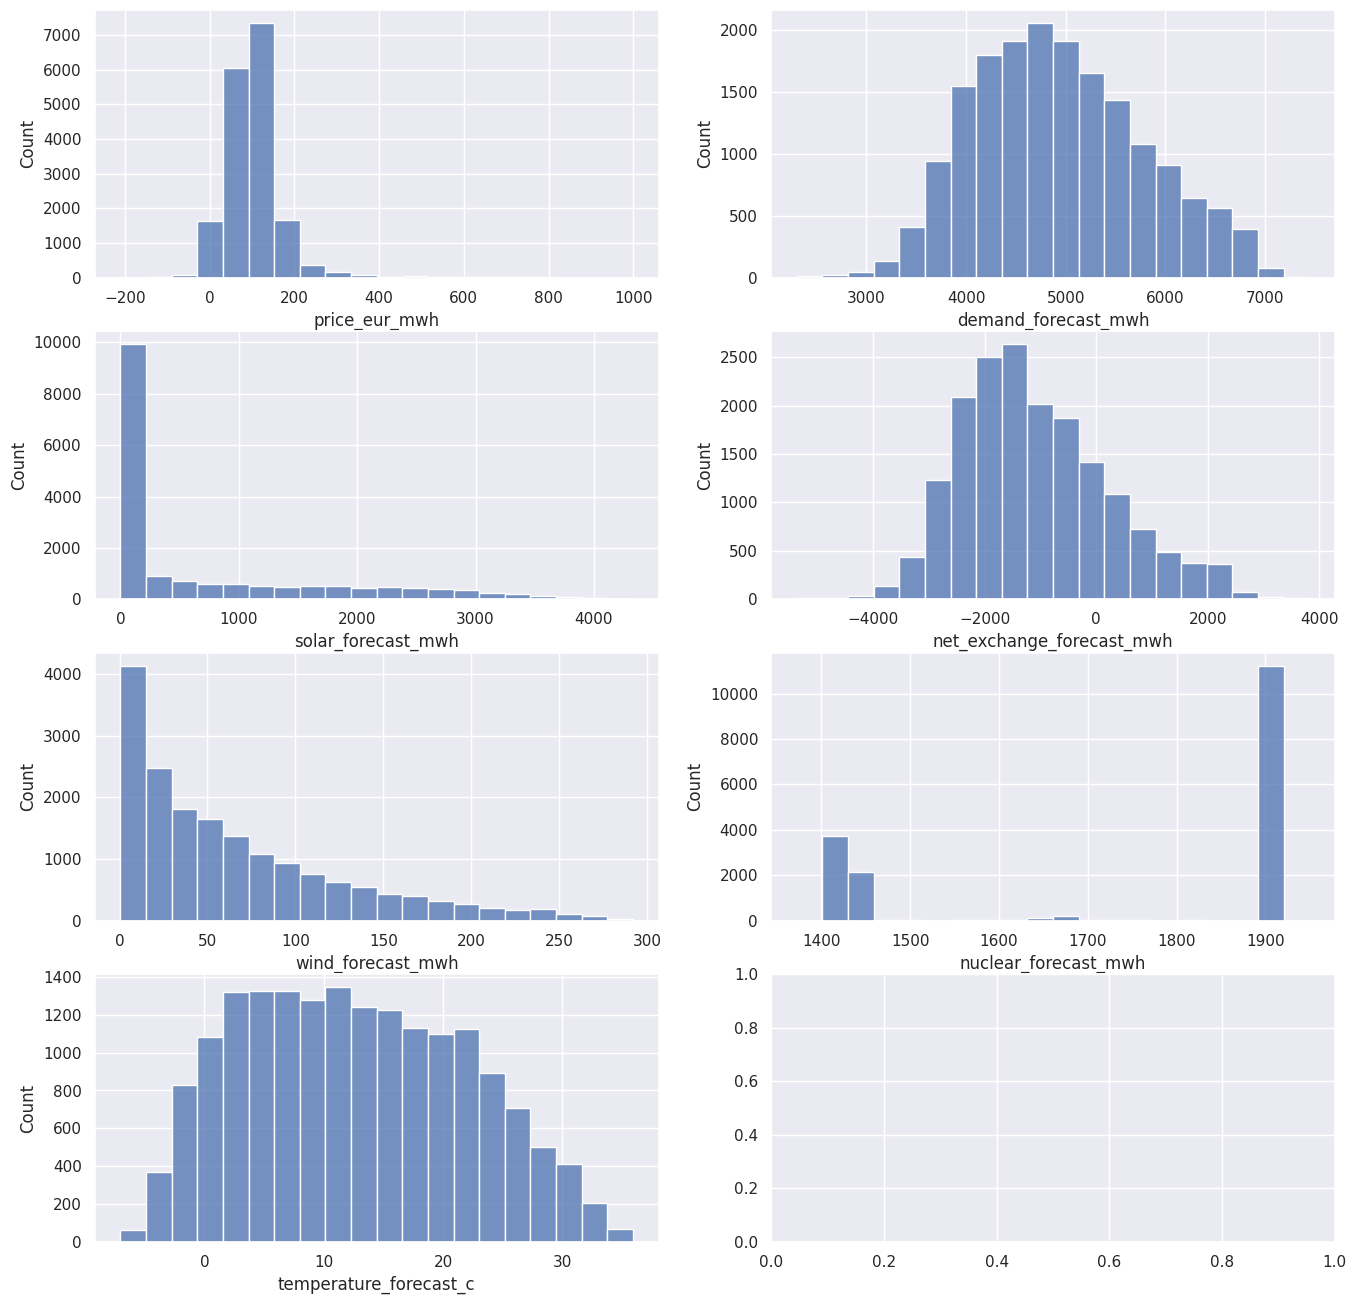

In [42]:
width = 2
height = int(np.ceil(len(num_columns)/width))
fig, ax = plt.subplots(nrows=height, ncols=width, figsize=(16,16))

for idx, column_name in enumerate(num_columns):
    plt.subplot(height,width, idx+1)
    sns.histplot(data=df, x=column_name, bins = 20);

### 3.2 Конструирование возможных признаков



**Базовые балансовые признаки**

Цена электроэнергии сильно зависит от баланса «спрос — предложение». Есть прогнозы выработки по источникам и прогноз спроса, но полезно явно посчитать чистые величины:

**supply_forecast_mwh** = solar_forecast_mwh + wind_forecast_mwh + nuclear_forecast_mwh — **суммарная генерация по этим источникам**.

**net_supply_forecast_mwh** = supply_forecast_mwh + net_exchange_forecast_mwh — **предложение с учётом перетоков**.

**demand_supply_gap_mwh** = demand_forecast_mwh - net_supply_forecast_mwh — **«дефицит/профицит» мощности**. Это один из самых сильных признаков: большой профицит (особенно из-за солнца/ветра) часто ведёт к низкой или отрицательной цене.

**renewables_share** = (solar_forecast_mwh + wind_forecast_mwh) / (supply_forecast_mwh + 1e-6) — **доля ВИЭ в прогнозируемой генерации**. Высокая доля ВИЭ часто коррелирует с отрицательными ценами в дневные часы.

**Относительные и нормированные признаки**

Модели (особенно линейные и деревья) любят признаки в понятном масштабе:

**demand_per_temp** = demand_forecast_mwh / (abs(temperature_forecast_c) + 1) — **спрос на единицу температуры** (помогает учесть нелинейности при экстремальных температурах).

**solar_per_demand** = solar_forecast_mwh / (demand_forecast_mwh + 1e-6) и аналогично wind_per_demand — **доля солнечной/ветровой генерации относительно спроса**.

**nuclear_share** = nuclear_forecast_mwh / (supply_forecast_mwh + 1e-6) — **доля базовой генерации** (АЭС обычно работают стабильно, это помогает модели понять «жёсткую» часть предложения).

**Временные и календарные признаки**
Даже если нет времени суток в явном виде, его почти всегда нужно добавить:

**hour_of_day (0–23), day_of_week (0–6), is_weekend (бинарный), month** — **сезонные и недельные паттерны цен** очень выражены.

**is_holiday (бинарный)** — **национальные праздники** часто дают аномальные цены.

**hour_sin, hour_cos** — **тригонометрическое кодирование часа суток** (чтобы модель корректно обрабатывала цикличность: 23 и 0 близки).

**day_sin, day_cos** — **аналогично для дня года**.

Если данные идут по часам, эти признаки критически важны: отрицательные цены чаще всего бывают днём, когда солнце активно, а спрос ещё не максимален.



**Признаки на основе температуры (погодные эффекты)**

Температура влияет и на спрос (отопление/охлаждение), и косвенно на цену:

**temp_squared** = temperature_forecast_c ** 2 — **нелинейный эффект:** при очень низких или высоких температурах спрос растёт непропорционально.

**is_cold** = (temperature_forecast_c < threshold) и

**is_hot** = (temperature_forecast_c > threshold) — бинарные пороги (например, < 5°C и > 25°C), чтобы модель явно видела экстремальные режимы.

**Перетоки и внешние рынки**

**net_export_share** = net_exchange_forecast_mwh / (demand_forecast_mwh + 1e-6) — **насколько экспорт/импорт значим относительно внутреннего спроса**

**Производные и агрегированные признаки по ВИЭ**

Поскольку отрицательные цены часто связаны с солнечной генерацией:

**solar_vs_demand** = solar_forecast_mwh / (demand_forecast_mwh + 1e-6) — **ключевой индикатор риска низкой цены**.
**wind_vs_demand, solar_plus_wind_vs_demand** — **суммарный вклад переменных ВИЭ относительно спроса**.

Если данные почасовые, **полезно добавить скользящие агрегаты: solar_mean_prev_24h, solar_max_prev_24h, solar_min_prev_24h** — чтобы модель видела не только прогноз, но и недавнюю динамику.

**Индикаторы «риска отрицательной цены»**

**Можно явно сконструировать бинарные признаки**, которые подсказывают модели, когда цена может быть отрицательной:

**high_solar_condition = (solar_forecast_mwh > demand_forecast_mwh * 0.7)** — например, если солнечная генерация покрывает большую часть спроса, риск отрицательной цены высок.

Аналогично можно сделать **high_renewables_condition на базе суммы солнца и ветра**.
Такие признаки не заменяют модель, но помогают деревьям быстрее находить нужные правила.

**Сезонные и трендовые признаки**


**trend_index** — простой линейный тренд (номер дня от начала выборки), чтобы модель могла учесть долгосрочные изменения цен.
seasonal_index (например, номер недели в году) — чтобы учесть годовые циклы.

In [43]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Конструирует дополнительные признаки для прогнозирования цены электроэнергии.
    Вход: DataFrame с колонками demand_forecast_mwh, solar_forecast_mwh,
          wind_forecast_mwh, nuclear_forecast_mwh, temperature_forecast_c,
          net_exchange_forecast_mwh. Также должна быть колонка datetime
          (или hour — час суток).
    Выход: DataFrame с новыми признаками.
    """
    df_new_feature = df.copy()

    # --- Баланс спроса и предложения ---
    df_new_feature['supply_forecast_mwh'] = (
        df_new_feature['solar_forecast_mwh']
        + df_new_feature['wind_forecast_mwh']
        + df_new_feature['nuclear_forecast_mwh']
    )

    df_new_feature['net_supply_forecast_mwh'] = (
        df_new_feature['supply_forecast_mwh'] + df_new_feature['net_exchange_forecast_mwh']
    )

    # Дефицит/профицит: положительный — дефицит, отрицательный — профицит
    df_new_feature['demand_supply_gap_mwh'] = (
        df_new_feature['demand_forecast_mwh'] - df_new_feature['net_supply_forecast_mwh']
    )

    # Доля ВИЭ (солнце + ветер) в прогнозируемой генерации
    denom = df_new_feature['supply_forecast_mwh'] + 1e-6
    df_new_feature['renewables_share'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh']) / denom
    )
    df_new_feature['nuclear_share'] = df_new_feature['nuclear_forecast_mwh'] / denom

    # --- Относительные признаки (на единицу спроса) ---
    denom_demand = df_new_feature['demand_forecast_mwh'] + 1e-6
    df_new_feature['solar_per_demand'] = df_new_feature['solar_forecast_mwh'] / denom_demand
    df_new_feature['wind_per_demand'] = df_new_feature['wind_forecast_mwh'] / denom_demand
    df_new_feature['renewables_per_demand'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh']) / denom_demand
    )
    df_new_feature['net_exchange_per_demand'] = (
        df_new_feature['net_exchange_forecast_mwh'] / denom_demand
    )

    # --- Температура и нелинейности ---
    df_new_feature['temp_squared'] = df_new_feature['temperature_forecast_c'] ** 2
    df_new_feature['is_cold'] = (df_new_feature['temperature_forecast_c'] < 5).astype(int)
    df_new_feature['is_hot'] = (df_new_feature['temperature_forecast_c'] > 25).astype(int)

    # --- Временные признаки ---
    if 'datetime' in df_new_feature.columns:
        dt = pd.to_datetime(df_new_feature['datetime'])
        df_new_feature['hour_of_day'] = dt.dt.hour
        df_new_feature['day_of_week'] = dt.dt.dayofweek
        df_new_feature['month'] = dt.dt.month
        df_new_feature['is_weekend'] = (dt.dt.dayofweek >= 5).astype(int)

        # Циклическое кодирование часа
        df_new_feature['hour_sin'] = np.sin(2 * np.pi * df_new_feature['hour_of_day'] / 24)
        df_new_feature['hour_cos'] = np.cos(2 * np.pi * df_new_feature['hour_of_day'] / 24)

        # Циклическое кодирование дня года
        day_of_year = dt.dt.dayofyear
        df_new_feature['day_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
        df_new_feature['day_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
    elif 'hour' in df_new_feature.columns:
        # Фолбэк: если datetime нет, но есть час — хотя бы час закодируем циклически
        df_new_feature['hour_of_day'] = df_new_feature['hour']
        df_new_feature['hour_sin'] = np.sin(2 * np.pi * df_new_feature['hour_of_day'] / 24)
        df_new_feature['hour_cos'] = np.cos(2 * np.pi * df_new_feature['hour_of_day'] / 24)

    # --- Индикаторы риска отрицательной цены ---
    df_new_feature['high_solar_condition'] = (
        df_new_feature['solar_forecast_mwh'] > df_new_feature['demand_forecast_mwh'] * 0.7
    ).astype(int)
    df_new_feature['high_renewables_condition'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh'])
        > df_new_feature['demand_forecast_mwh'] * 0.8
    ).astype(int)

    return df_new_feature

In [44]:
def save_dataset(
    df: pd.DataFrame,
    path: str | Path,
    fmt: str = 'parquet',
    timestamped: bool = False,
    **kwargs,
) -> Path:
    """
    Сохраняет датасет на диск в выбранном формате.

    Параметры:
        df          — датафрейм для сохранения;
        path        — путь к файлу (или к директории, если timestamped=True);
        fmt         — 'parquet' | 'csv' | 'feather';
        timestamped — если True, добавляет к имени файла метку времени,
                      чтобы версии не перезаписывали друг друга;
        **kwargs    — доп. аргументы для to_parquet/to_csv/to_feather.

    Возвращает фактический путь к сохранённому файлу.
    """
    path = Path(path)
    fmt = fmt.lower().strip('.')

    if fmt not in {'parquet', 'csv', 'feather'}:
        raise ValueError(f"Неподдерживаемый формат: {fmt!r}. Доступны: parquet, csv, feather")

    if timestamped:
        # Если передали директорию — кладём файл в неё с осмысленным именем
        if path.suffix:
            path = path.with_name(f"{path.stem}")
        stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
        path = path.with_name(f"{path.name}_{stamp}.{fmt}")

    path.parent.mkdir(parents=True, exist_ok=True)

    if fmt == 'parquet':
        df.to_parquet(path, index=False, **kwargs)
    elif fmt == 'csv':
        df.to_csv(path, index=False, **kwargs)
    elif fmt == 'feather':
        df.to_feather(path, **kwargs)

    size_kb = path.stat().st_size / 1024
    print(f"Сохранено: {path} ({size_kb:.1f} КБ, {len(df)} строк, {df.shape[1]} колонок)")
    return path

In [45]:
df_new_feature = engineer_features(df)

df_new_feature.to_csv('/content/drive/MyDrive/year_project/df_new_feature.csv', index=False)

**Практические советы по отбору признаков**

Сначала физика, потом статистика. Признаки вроде solar_excess_vs_demand и supply_tightness имеют понятную экономическую интерпретацию — их проще отладить и объяснить бизнесу.
Проверяй утечки (data leakage). Если используешь скользящие окна или исторические агрегаты, убедись, что на момент прогноза эти значения уже известны.
Масштабирование. Для линейных моделей и нейросетей полезно масштабировать признаки (StandardScaler/MinMaxScaler), особенно такие, как tightness_log, temp_squared.
Отбор признаков. Используй корреляции, важность признаков (feature importance) в градиентном бустинге или L1-регуляризацию, чтобы убрать дублирующиеся признаки (например, не оставляй одновременно solar_per_demand и solar_excess_vs_demand, если они сильно коррелируют).

### 3.3 Корреляция числовых признаков

In [46]:
cm = sns.color_palette("vlag", as_cmap=True)

df[num_columns].corr().style.background_gradient(cmap=cm, vmin = -1, vmax=1)

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
price_eur_mwh,1.000000,0.588128,-0.401941,-0.427457,-0.080483,0.079333,-0.145900
demand_forecast_mwh,0.588128,1.000000,-0.267465,-0.578691,0.049818,0.040131,-0.402458
solar_forecast_mwh,-0.401941,-0.267465,1.000000,0.703014,-0.183564,-0.048918,0.462534
net_exchange_forecast_mwh,-0.427457,-0.578691,0.703014,1.000000,-0.133620,0.094415,0.435270
wind_forecast_mwh,-0.080483,0.049818,-0.183564,-0.133620,1.000000,0.031541,-0.158097
nuclear_forecast_mwh,0.079333,0.040131,-0.048918,0.094415,0.031541,1.000000,-0.114606
temperature_forecast_c,-0.145900,-0.402458,0.462534,0.435270,-0.158097,-0.114606,1.000000


**Спрос — главный линейный драйвер цены (r = 0,59)**. Спрос почти не коррелирует с остальными признаками по величине (кроме температуры, −0,40).

**Солнце (−0,40) и сальдо обмена (−0,43) давят цену вниз**. Оба коррелируют с ценой умеренно-сильно отрицательно. Механика: в солнечные часы Венгрия экспортирует профицит → цена падает вплоть до отрицательных значений.

**Сильная мультиколлинеарность солнца и сальдо обмена (r = 0,70)**. Это ключевой методологический вывод. Механика связи: в солнечные часы Венгрия экспортирует профицит → сальдо становится менее отрицательным/положительным, а солнце растёт, и оба признака с ценой связаны отрицательно. Для линейных моделей это означает, что один из признаков малоинформативен сверх другого; для деревьев это не критично, но важно знать при интерпретации важностей признаках.

**Ветер (−0,08) и атом (+0,08) линейно почти не влияют**. Ветер — потому что мал по величине (~1% спроса), атом — потому что меняется дискретными ступенями (1900/1440/1640).

**Температура**. Холод и жара поднимают спрос, тепло — нет. Температура сильно коррелирует с солнцем (0,46) и сальдо (0,44) — это просто лето: жаркие дни = много солнца = экспорт профицита.

**Атом vs спрос (0,04), атом vs солнце (−0,05)**. Атом почти не коррелирует с другими признаками.

**Следствия для моделей**

**Главный признак — residual load (спрос − солнце − ветер − атом)**

 **базовый класс — нелинейные модели (бустинг)**

### 3.4 Исследования временных рядов


In [47]:
# Проверим монотонность, дубликаты и пропуски
print(f'монтонность: {df.index.is_monotonic_increasing}')
print(f'дубликаты: {df.index.has_duplicates}')
print(f'пропуски: {df.isna().sum().sum()}')

монтонность: True
дубликаты: False
пропуски: 0


### Введение индексов-дат

####  Задание временной индексации

1. **Переименование колонки**:  
   Колонка `'timestamp'` переименована в `'time'` для удобства и читаемости.

2. **Преобразование к типу datetime**:  
   Преобразовали `'time'` к типу временных меток `datetime`. Это необходимо для корректной работы с временными рядами.

3. **Конвертация и установка временного индекса**:  
   Колонка `'time'` установлена в качестве индекса DataFrame. Это позволяет использовать удобные методы для работы с временными данными, например:  
   - `df.loc['2025']` — выборка за 2025 год,  
   - `df.resample('D')` — агрегация по дням.
     
4. **Удаление часового пояса (UTC)**:  
   Из индекса удалён часовой пояс (например, `+00:00`), чтобы получить "наивное" время (`naive datetime`) в формате `2025-11-25 23:00:00`.  

   
   
5. **Проверка частоты данных**:  
   Убедимся, что временной индекс имеет **почасовую частоту** (`'H'`).
        
6. **Проверка**:  
   Оценка структуры данных.

In [48]:
df = df.rename(columns={'timestamp': 'time'})
df['time'] = pd.to_datetime(df['time'], utc=True)   # utc=True надёжно для любого формата
df = df.set_index('time')
df.index = df.index.tz_convert('Europe/Budapest').tz_localize(None)

step = df.index.to_series().diff().dt.total_seconds()
print((step.dropna() == 3600).mean())
print(df.groupby(df.index.date).size().value_counts().to_dict())
print(len(df), df.index.duplicated().sum(), df.isna().sum().sum())

0.9997719888274526
{24: 727, 23: 2, 25: 2}
17544 2 0


**Дни: {24: 727, 23: 2, 25: 2} — два перехода на летнее время** (сутки из 23 часов: март 2024 и март 2025) **и два на зимнее** (сутки из 25 часов: октябрь 2024 и октябрь 2025)**

#### диапазон дат

In [50]:
print(f"Диапазон дат: {df.index.min()} — {df.index.max()}")
print(f"Частота (если установлена): {df.index.freq}")

Диапазон дат: 2024-01-01 00:00:00 — 2025-12-31 23:00:00
Частота (если установлена): None


## Визуализация временного ряда

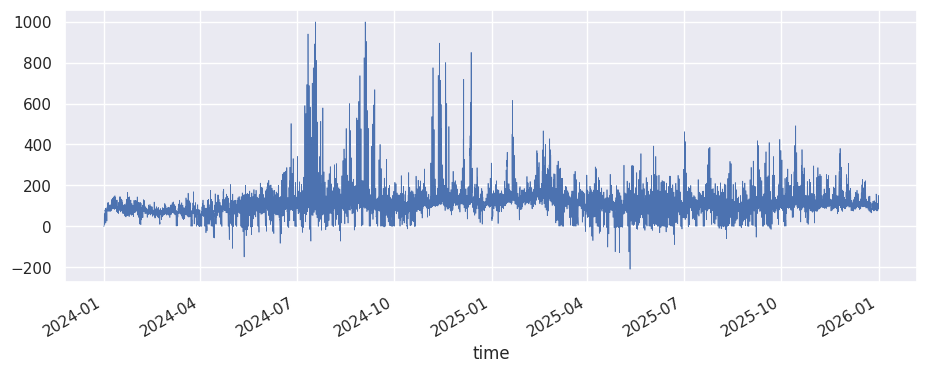

In [51]:
# Письмаров
df['price_eur_mwh'].plot(linewidth=0.5);

** На графике видно**

**Два режима волатильности**. Первая половина 2024 — относительно спокойная (основная масса значений 0–150 EUR/MWh). С июля 2024 по январь 2025 — период экстремальной волатильности: пики регулярно выходят за 800 и достигают 1000 EUR/MWh (июль–август и конец декабря 2024). С 2025 года ряд возвращается к умеренному режиму — пики редко превышают 400–500, хотя в конце 2025 опять намечается рост.
Отрицательные цены заметны как короткие «иглы» ниже нуля, самая глубокая — около −200 EUR/MWh весной 2025. Их мало на фоне общей картины, что согласуется со статистикой (3,7% часов).
Устойчивого тренда нет. Средний уровень колеблется вокруг ~100 EUR/MWh весь период; изменчивость — в амплитуде, а не в уровне. Это важный аргумент против trend_index как признака (он у вас есть в списке сконструированных) — линейного дрейфа цены данные не показывают.
Гетероскедастичность. Разброс ряда резко меняется по периодам: спокойные месяцы и месяцы «штормов». Для модели это значит, что на спокойных периодах ошибки будут маленькими, на волатильных — большими, и общая метрика будет доминирована спокойными часами. Отсюда — контроль ошибки на хвостах.
Сезонность пиков, а не уровней. Экстремумы приурочены к конкретным сезонам: летние вечера (июль–август 2024) и зимние пики (декабрь 2024 — январь 2025). Летом и зимой 2025 пики есть, но ниже — год-в-год режим рынка меняется.

Также визуализируем и остальные столбцы

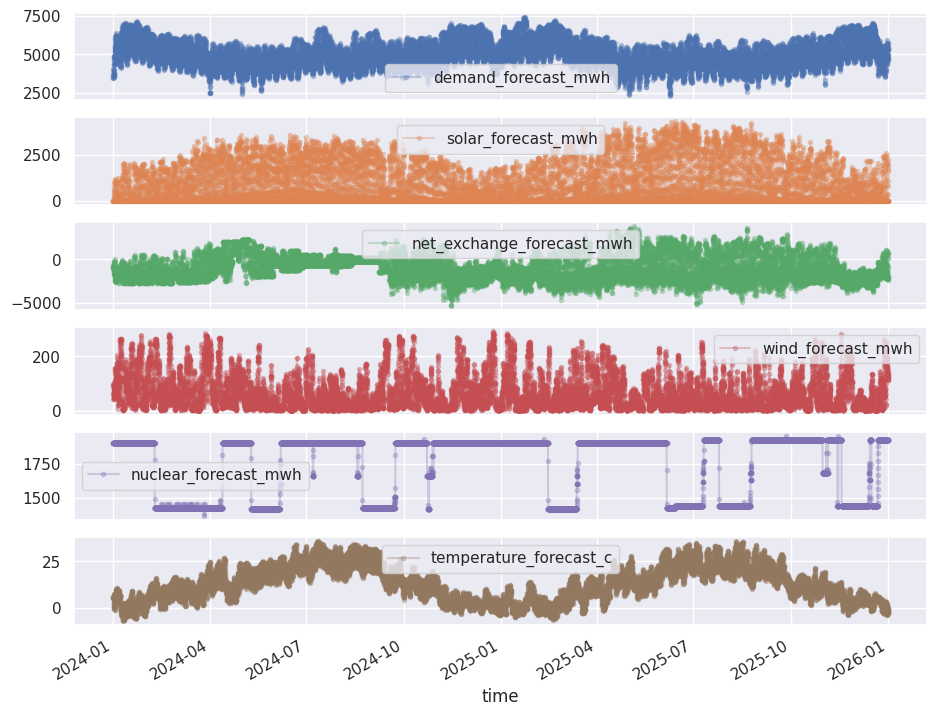

In [52]:
cols_plot = ['demand_forecast_mwh', 'solar_forecast_mwh', 'net_exchange_forecast_mwh','wind_forecast_mwh','nuclear_forecast_mwh', 'temperature_forecast_c']
axes = df[cols_plot].plot(marker='.', alpha=0.3, linestyle='-', figsize=(11, 9), subplots=True)
# for ax,col in axes:
#     ax.set_ylabel('Daily Totals (GWh)')

**Сезонные профили спроса и солнца находятся в противофазе внутри суток и синхронны по году в Anti-фазе вклада**: зимой спрос максимален, а солнца мало → высокие цены; летом днём солнце велико, а бизнес-спрос в выходные низок → отрицательные цены. Остаточная нагрузка (спрос − солнце − ветер − атом) соберёт эту фазировку в один признак — она видна на этом графике лучше, чем в любых отдельных корреляциях.

**Перетоки — «демпфер», привязанный к солнцу:** зимний импорт поддерживает цену сверху, летний экспорт давит вниз. Самостоятельного сезонного сигнала сверх солнца у net_exchange мало — для линейных моделей один из пары избыточен.

**Атом — независимый от погоды сигнал:** его связь с ценой определяется графиком ремонтов, и именно в периоды плато на пониженном уровне (~1440 вместо ~1900) остаточная нагрузка систематически выше на ~460 MWh — это фичерованный, а не шумовой эффект.

**Ветер на годовом масштабе не даёт ничего:** его полезность — только на суточном горизонте внутри конкретных дней.

* Посмотрим в какие месяцы цена высокая/низкая → зима vs лето.
* Посмотрим в какое время суток пик цены → утро и вечер
* Проверим в какие дни  пик цены → будни vs выходные.

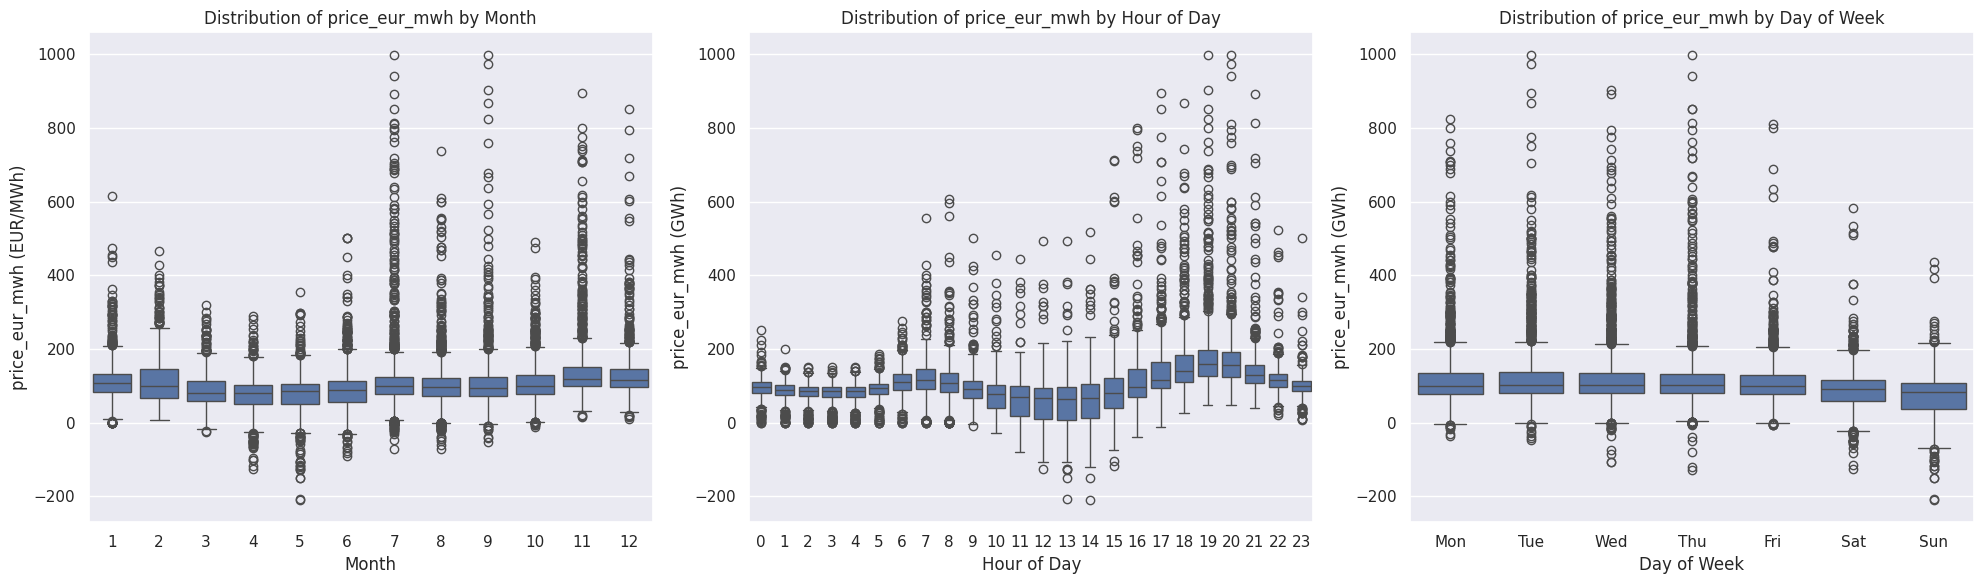

In [54]:
# Подготовка данных
df['month'] = df.index.month
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek  # 0=понедельник, 6=воскресенье

# Создаём 3 сабплота горизонтально
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# График 1: по месяцам
sns.boxplot(x='month', y='price_eur_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of price_eur_mwh by Month')
ax1.set_xlabel('Month')
ax1.set_ylabel('price_eur_mwh (EUR/MWh)')

# График 2: по часам
sns.boxplot(x='hour', y='price_eur_mwh', data=df, ax=ax2)
ax2.set_title('Distribution of price_eur_mwh by Hour of Day')
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('price_eur_mwh (GWh)')

# График 3: по дням недели
sns.boxplot(x='day_of_week', y='price_eur_mwh', data=df, ax=ax3)
ax3.set_title('Distribution of price_eur_mwh by Day of Week')
ax3.set_xlabel('Day of Week')
ax3.set_ylabel('price_eur_mwh (GWh)')
ax3.set_xticks(range(7))
ax3.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])

plt.tight_layout()
plt.show()

**По месяцам (левая панель):** медианы невысоки почти везде (60–130), а различие месяцев — в хвостах. Ящик заметно шире и медианы выше в декабре–феврале и особенно в июле–августе; самые «дешёвые» месяцы — апрель–май, где медианы минимальны и часть распределения уходит ниже нуля (выбросы до −210 видны у месяцев 4–6). Экстремальные выбросы (800–1000 EUR/MWh) приурочены к июлю–августу, октябрю–ноябрю и январю. То есть профиль не монотонный «лето дорого», а U-образный: дорого зимой и в разгар лета, дёшево весной и осенью — зимой гонит отопление, летом кондиционеры, а в межсезонье и спрос ниже, и солнца уже много.

**По часам (центральная панель):** виден двугорбый профиль. Ночь 0–5 ч — дёшево и стабильно. Утренний подъём к 8–9 ч. Середина дня 10–14 ч — умеренно. Главный пик — вечер 17–21 ч. К 22–23 ч спад. То есть пиков у цены два, а «антипик» — полдень.

**По дням недели (правая панель):** медианы будней (пн–пт) почти одинаковы (~100–115), облако выбросов огромное с понедельника по четверг (пики до 1000 на вт и чт). В выходные картина иная: медианы чуть ниже, облако выбросов заметно беднее, а отрицательные выбросы концентрируются в субботу и особенно воскресенье (хвост вниз до −210). То есть будни дают вечернюю волатильность, выходные — дневные провалы.

### Анализ редких регулярных событий

Text(0, 0.5, 'price_eur_mwh (GWh)')

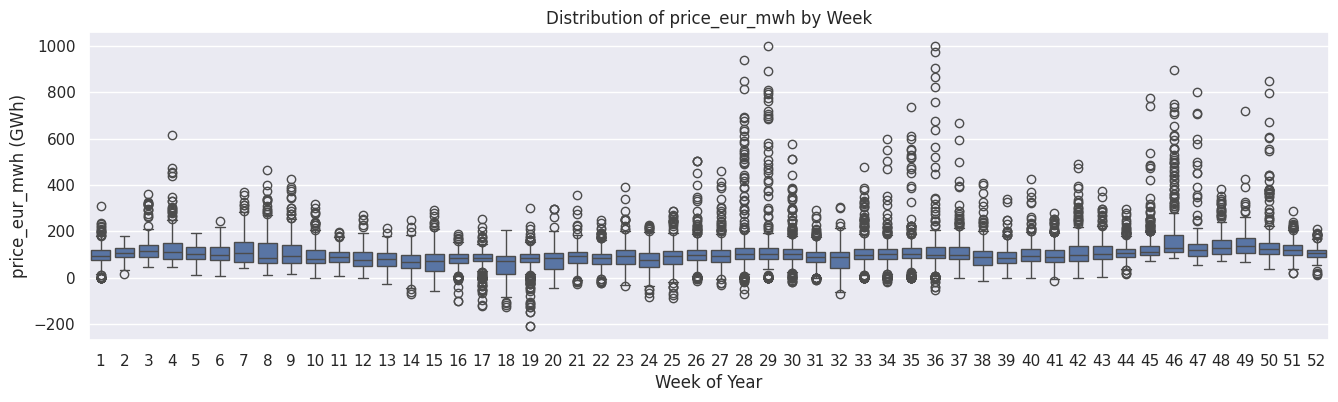

In [56]:
df['week'] = df.index.isocalendar().week
fig, ax1 = plt.subplots(1, 1, figsize=(16, 4))
sns.boxplot(x='week', y='price_eur_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of price_eur_mwh by Week')
ax1.set_xlabel('Week of Year')
ax1.set_ylabel('price_eur_mwh (GWh)')

**Зима, недели 1–10 (январь–начало марта).** Самые высокие медианы за год (~100–130 EUR/MWh), облака выбросов на неделях 7–9 (до 400–500). Это период отопления: высокий спрос при малом солнце держит и уровень, и волатильность.

**Весна, недели 12–20 (середина марта–середина мая).** Самая дешёвая зона года: медианы падают до ~60–70, ящики узкие. При этом неделя 19 (начало мая) — главная зона отрицательных цен: выбросы уходят ниже −200. Это классическая весенняя комбинация — солнце уже сильное, спрос межсезонный, выходные.

**Лето, недели 27–37 (июль–середина сентября)**. Два локализованных «шторма»: недельные кластеры 28–29 (середина июля) и 35–36 (конец августа) дают облака выбросов до 1000 EUR/MWh, при этом медианы не так высоки (~70–100) — то есть летние экстремумы это не «дорогие недели целиком», а отдельные вечерние часы внутри них. Между ними недели 30–34 спокойные. Это уточнение к помесячному графику: «июль–август волатильны» на самом деле означает 3–4 конкретные недели волн жары.

**Осень, недели 44–50 (ноябрь–декабрь).** Вторая зона повышенной волатильности: медианы возвращаются к ~100–130, выбросы до 700–900 на неделях 45–47 и 49–50. Начало отопительного сезона.

**Неделя 52 (конец декабря).** Заметный провал: медиана низкая, ящики узкие — рождественско-новогодний период снижает промышленную нагрузку.

#4. ГЛАВНЫЕ ВЫВОДЫ ЕDA

##4.1 О данных

### 4.1.1 Качество данных.
17 544 почасовых записи за 2024–2025, пропусков, дубликатов нет; шаг ровно один час, кроме суток перехода на летнее/зимнее время (23 и 25 часов) — данные готовы к моделированию без восстановления. Индекс приведён к локальному времени Будапешта — все суточные паттерны корректны.

### 4.1.2 Целевая переменная.
Цена скошена вправо (асимметрия ~3,3), среднее 104,7 при медиане 97,7. Два «хвоста» имеют физическую природу и не являются ошибками: отрицательные цены (минимум −210, около 3,7% часов) — солнечный профицит в дневные часы выходных; экстремальные пики (до 999) — дефицит мощности в летние и зимние вечера. Удалять их нельзя — их нужно уметь предсказывать. Логарифм неприменим, симметризация — arcsinh. Устойчивого линейного тренда уровня нет (аргумент против trend_index), меняется амплитуда колебаний: 2024 — волатильный год, 2025 — дороже в среднем, но спокойнее.

###4.1.3 Суточный и сезонный профиль.

Профиль цены по часам двугорбый: ночные часы (0–5) дёшевы и стабильны, утренний пик (8–10), «антипик» в полдень (10–14 — зона отрицательных цен) и главный вечерний пик (17–21, хвосты до 1000). По месяцам профиль U-образный: дорого зимой (отопление) и в июле–августе (кондиционирование), дёшево весной (апрель–май, где сосредоточены отрицательные цены). По дням недели медианы близки, но будни волатильнее, а отрицательные цены концентрируются в выходные. Единый суточный профиль не описывает данные — сезонность взаимодействует с часом и днём недели.

###4.1.4 Признаки и их природа.
Спрос — главный линейный драйвер цены (r = 0,59). Солнце (−0,40) и сальдо обмена (−0,43) давят цену вниз; между собой они сильно коррелируют (0,70 — мультиколлинеарность: оба управляются одним сезонным механизмом). Ветер мал (~1% спроса) и линейно не виден. Атом — дискретные уровни мощности (полная ~1900, ремонты ~1440), независим от погоды, требует категориального кодирования. Температура имеет U-образный эффект на спрос — линейная подача неверна. Главный структурный сигнал — баланс спроса и генерации, поэтому ключевой конструируемый признак — остаточная нагрузка (спрос минус солнце, ветер и атом).

## 4.2 О моделях
### 4.2.1 Класс моделей.
Связь цены с признаками нелинейна — базовый класс: градиентный бустинг (LightGBM/XGBoost/CatBoost). Масштабирование для бустинга не нужно; для линейных моделей и нейросетей — обязательная стандартизация в пайплайне.

### 4.2.2 Признаки.

Обязательный минимум: hour_of_day (циклически или категориально), is_weekend, is_holiday, month, остаточная нагрузка, solar_per_demand, флаги is_cold/is_hot, режим атома как категория. Убрать дубли (solar_per_demand ↔ solar_vs_demand), не включать trend_index.

### 4.2.3 Валидация.
Только по времени: train — 2024, test — 2025 (или expanding window). Случайный сплит смешивает режимы и завышает качество. Дополнительно проверять устойчивость модели на обоих годах — режимы рынка различаются.

### 4.2.4 Лаги.

Прогноз публикуется до полудня, поэтому лаги цены доступны только с шагом ≥ 24 часов; скользящие агрегаты по цене — только с лагом ≥ 24 ч, иначе утечка.

### 4.2.5 Метрика.
Помимо MAE/RMSE контролировать ошибку отдельно на хвостах (цена ≤ 0 и > 300 EUR/MWh) — например, доля часов с ошибкой > 50 EUR/MWh в хвостовых зонах.

### 4.2.6 Выбросы.
Не удалять: обе крайности — предсказуемые рыночные режимы. Возможно, отдельная ветка/модель для вероятности отрицательной цены (классификатор поверх регрессии).